In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import math
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import sys
sys.path.append(str(Path.cwd().parent))
from config import SEED
path = Path.cwd().parents[1]/ "data" / "real_data"


In [3]:
YEARS = [2011, 2012, 2013, 2014, 2015]
TARGETS = ["CO", "NOX"]
FEATURES = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "TEY", "CDP"]


def load_gas_turbine(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(Path(path) / "regression" / "gas_turbine.parquet")
    df = df.rename(columns={f"f{i}": c for i, c in enumerate(FEATURES)} | {"target": "NOX"})
    df = df[["year"] + FEATURES + TARGETS]
    df["year"] = pd.Categorical(df["year"], categories=YEARS, ordered=True)
    return df

In [4]:
df = load_gas_turbine(path)
feature_cols = [c for c in df.columns if c not in TARGETS + ["year"]]
num_cols = feature_cols + TARGETS

In [5]:
df.head()

,year,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,2011,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,2011,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,2011,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,2011,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,2011,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


In [6]:
print(df.shape)
print(pd.concat({"count": df["year"].value_counts(sort=False), "share": df["year"].value_counts(sort=False, normalize=True).round(4)}, axis=1))
print(df.isna().sum().sum())
print(df[num_cols].describe().T)

(36733, 12)
      count   share
year               
2011   7411  0.2018
2012   7628  0.2077
2013   7152  0.1947
2014   7158  0.1949
2015   7384  0.2010
0
        count         mean        std          min        25%        50%  \
AT    36733.0    17.712726   7.447451    -6.234800    11.7810    17.8010   
AP    36733.0  1013.070165   6.463346   985.850000  1008.8000  1012.6000   
AH    36733.0    77.867015  14.461355    24.085000    68.1880    80.4700   
AFDP  36733.0     3.925518   0.773936     2.087400     3.3556     3.9377   
GTEP  36733.0    25.563801   4.195957    17.698000    23.1290    25.1040   
TIT   36733.0  1081.428084  17.536373  1000.800000  1071.8000  1085.9000   
TAT   36733.0   546.158517   6.842360   511.040000   544.7200   549.8800   
TEY   36733.0   133.506404  15.618634   100.020000   124.4500   133.7300   
CDP   36733.0    12.060525   1.088795     9.851800    11.4350    11.9650   
CO    36733.0     2.372468   2.262672     0.000388     1.1824     1.7135   
NOX   3673

In [7]:
df[num_cols].corr().style.background_gradient(cmap="coolwarm")

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
AT,1.000000,-0.406601,-0.476291,0.251974,0.045851,0.183706,0.281869,-0.091152,0.015287,-0.174326,-0.558174
AP,-0.406601,1.000000,-0.015184,-0.040363,0.057533,-0.005390,-0.225601,0.118224,0.102636,0.067050,0.191938
AH,-0.476291,-0.015184,1.000000,-0.147840,-0.235153,-0.221809,0.022965,-0.137360,-0.196275,0.106586,0.164617
AFDP,0.251974,-0.040363,-0.147840,1.000000,0.678485,0.691292,-0.466882,0.665483,0.702568,-0.448425,-0.188247
GTEP,0.045851,0.057533,-0.235153,0.678485,1.000000,0.874234,-0.699703,0.964127,0.978470,-0.518909,-0.201630
TIT,0.183706,-0.005390,-0.221809,0.691292,0.874234,1.000000,-0.380862,0.910297,0.908469,-0.706275,-0.213865
TAT,0.281869,-0.225601,0.022965,-0.466882,-0.699703,-0.380862,1.000000,-0.682396,-0.706438,0.058353,-0.092791
TEY,-0.091152,0.118224,-0.137360,0.665483,0.964127,0.910297,-0.682396,1.000000,0.988778,-0.569813,-0.116127
CDP,0.015287,0.102636,-0.196275,0.702568,0.978470,0.908469,-0.706438,0.988778,1.000000,-0.551027,-0.171256
CO,-0.174326,0.067050,0.106586,-0.448425,-0.518909,-0.706275,0.058353,-0.569813,-0.551027,1.000000,0.340606


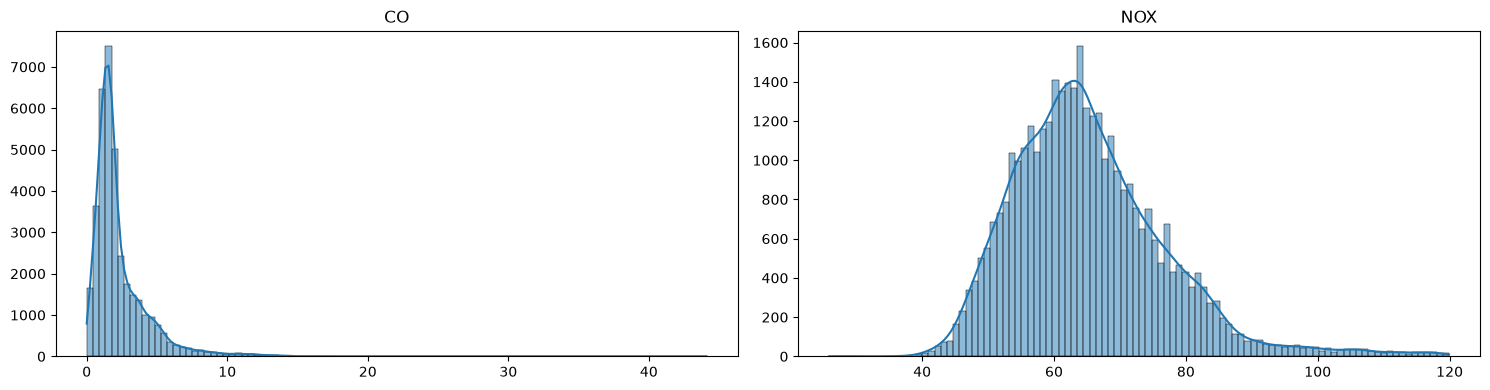

In [8]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(15, 4))

for ax, col in zip(axes, TARGETS):
    sns.histplot(data=df, x=col, bins=100, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

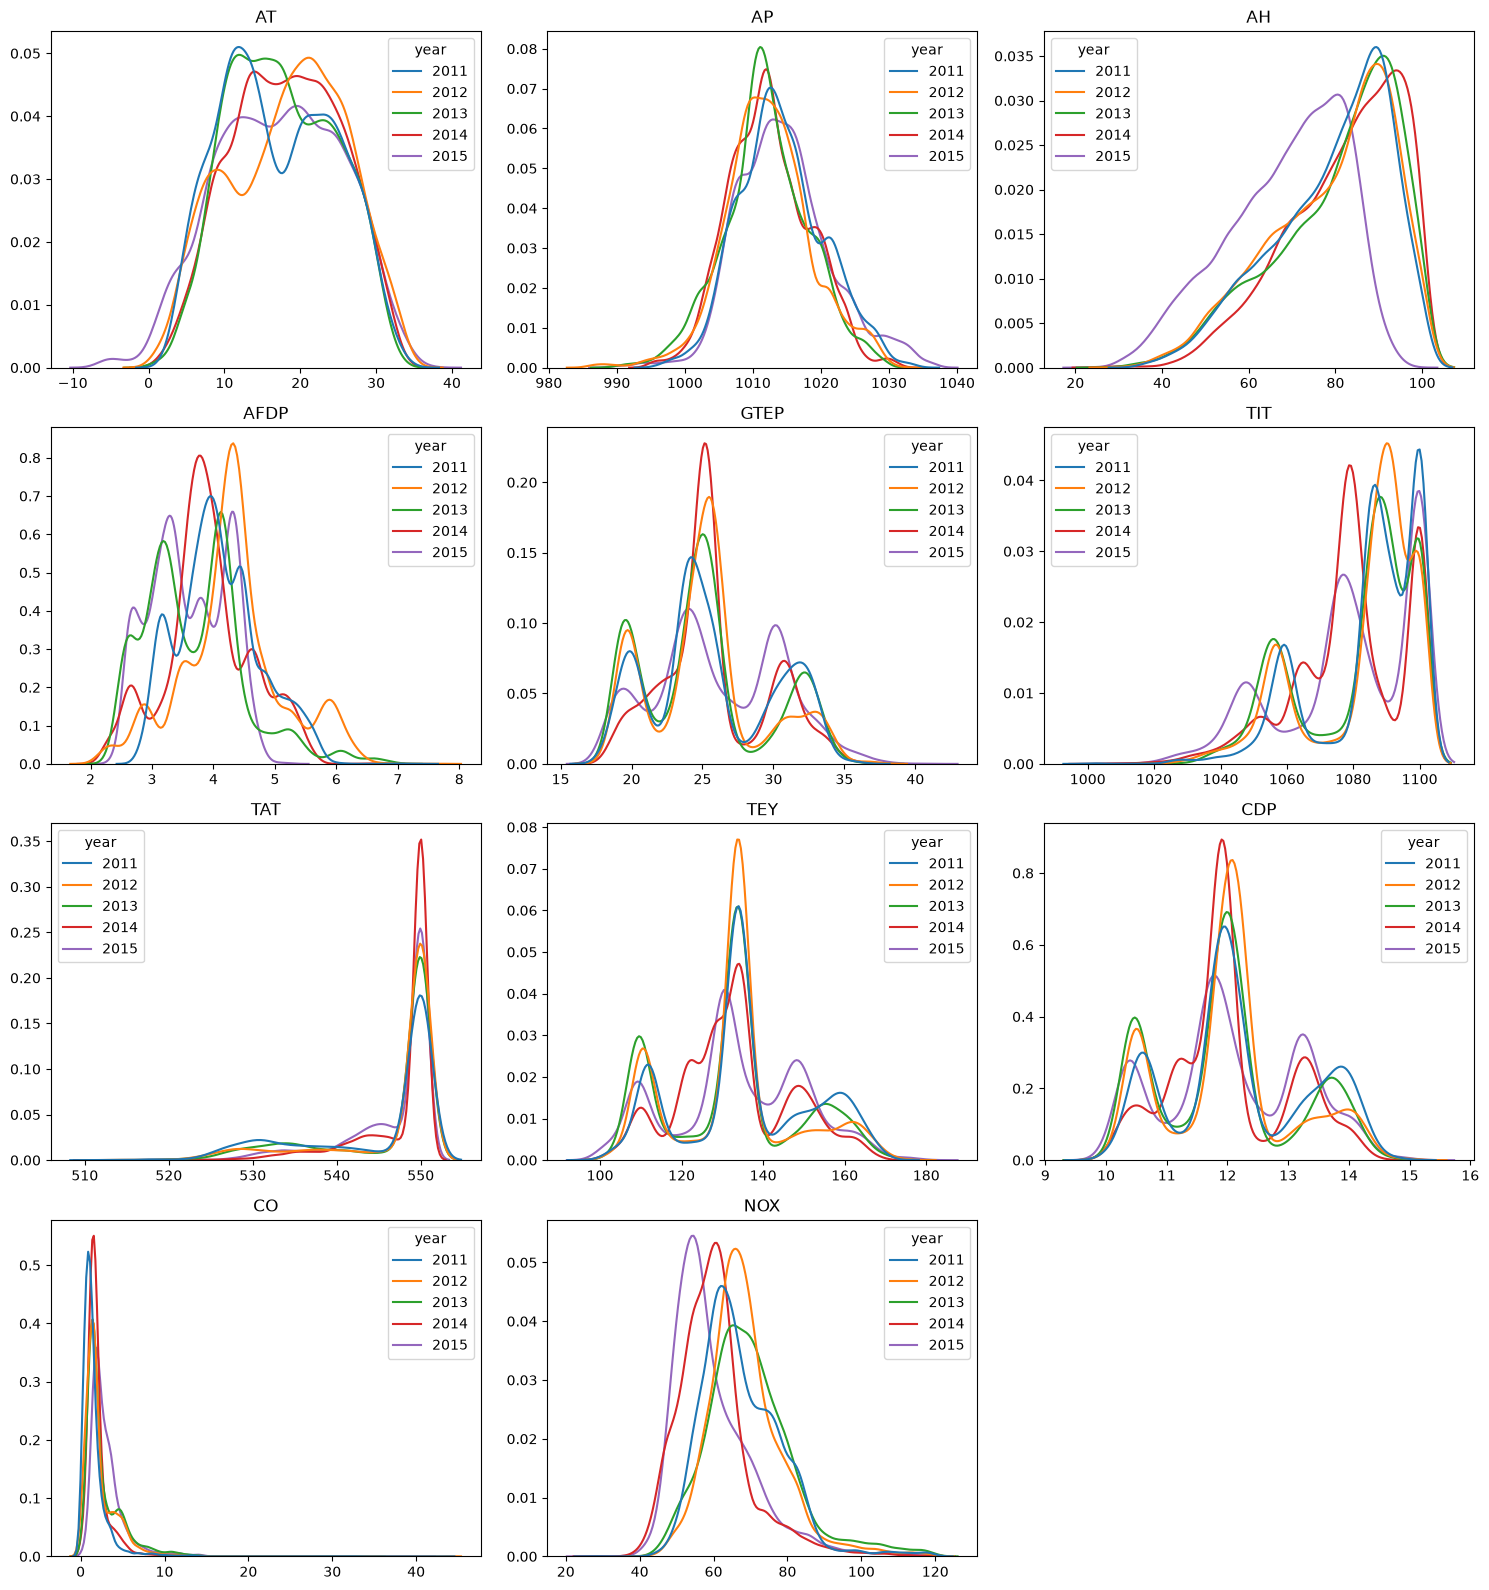

In [9]:
ncols = 3
nrows = math.ceil(len(num_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.kdeplot(data=df, x=col, hue="year", common_norm=False, warn_singular=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

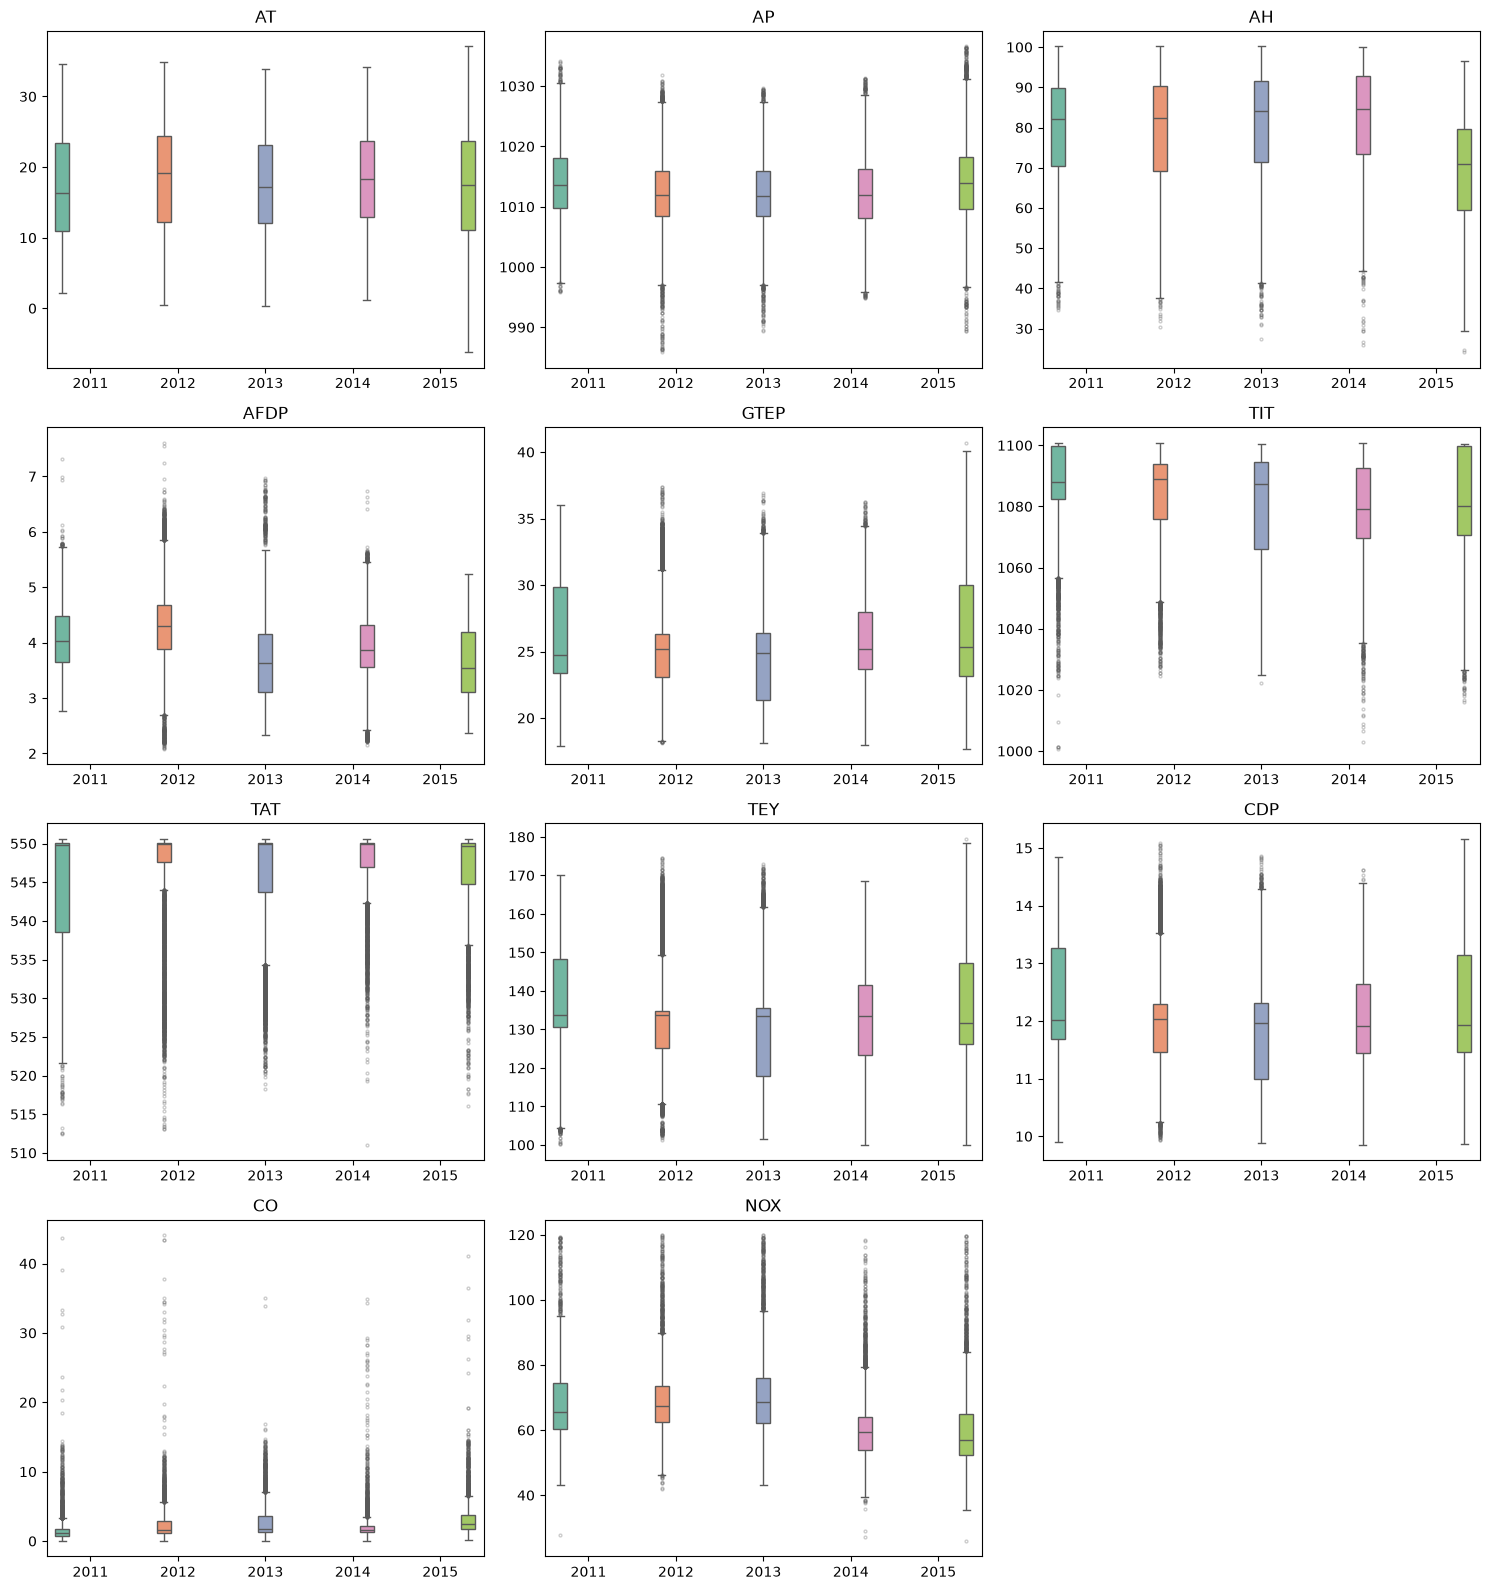

In [10]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="year", y=col, hue="year", palette="Set2",
                legend=False, ax=ax, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
g = df.groupby("year", observed=True)[num_cols]
stats_year = pd.concat({"skośność": g.skew().T, "kurtoza": g.kurt().T}, axis=1).round(3)
stats_year

skośność                              kurtoza                          \
year     2011   2012   2013   2014   2015     2011    2012    2013    2014   
AT      0.121 -0.181  0.110 -0.039 -0.118   -1.057  -0.862  -0.893  -0.827   
AP      0.258 -0.013 -0.057  0.210  0.392   -0.142   0.828   0.198  -0.113   
AH     -0.701 -0.662 -0.805 -0.739 -0.542   -0.223  -0.341  -0.076  -0.013   
AFDP    0.387  0.145  0.827  0.063  0.017   -0.249   0.317   0.968  -0.037   
GTEP    0.268  0.469  0.438  0.431  0.108   -0.975  -0.158  -0.696  -0.357   
TIT    -1.178 -1.091 -0.820 -0.666 -0.704    0.764   0.040  -0.610   0.410   
TAT    -1.178 -1.867 -1.513 -2.260 -1.915   -0.054   2.267   0.857   5.243   
TEY     0.026  0.252  0.162  0.209 -0.054   -0.717  -0.157  -0.685  -0.250   
CDP     0.190  0.305  0.297  0.330  0.059   -0.888  -0.222  -0.724  -0.370   
CO      7.334  6.171  2.522  6.969  3.947  104.994  72.101  12.960  74.457   
NOX     1.075  1.211  1.024  1.322  1.619    2.361   3.029   1.963   3.601   

              
year    2015  
AT    -0.681  
AP     0.550  
AH    -0.468  
AFDP  -1.160  
GTEP  -0.841  
TIT   -0.443  
TAT    3.439  
TEY   -0.599  
CDP   -0.868  
CO    34.324  
NOX    3.842

In [12]:
sample = df.sample(n=10000, random_state=SEED)

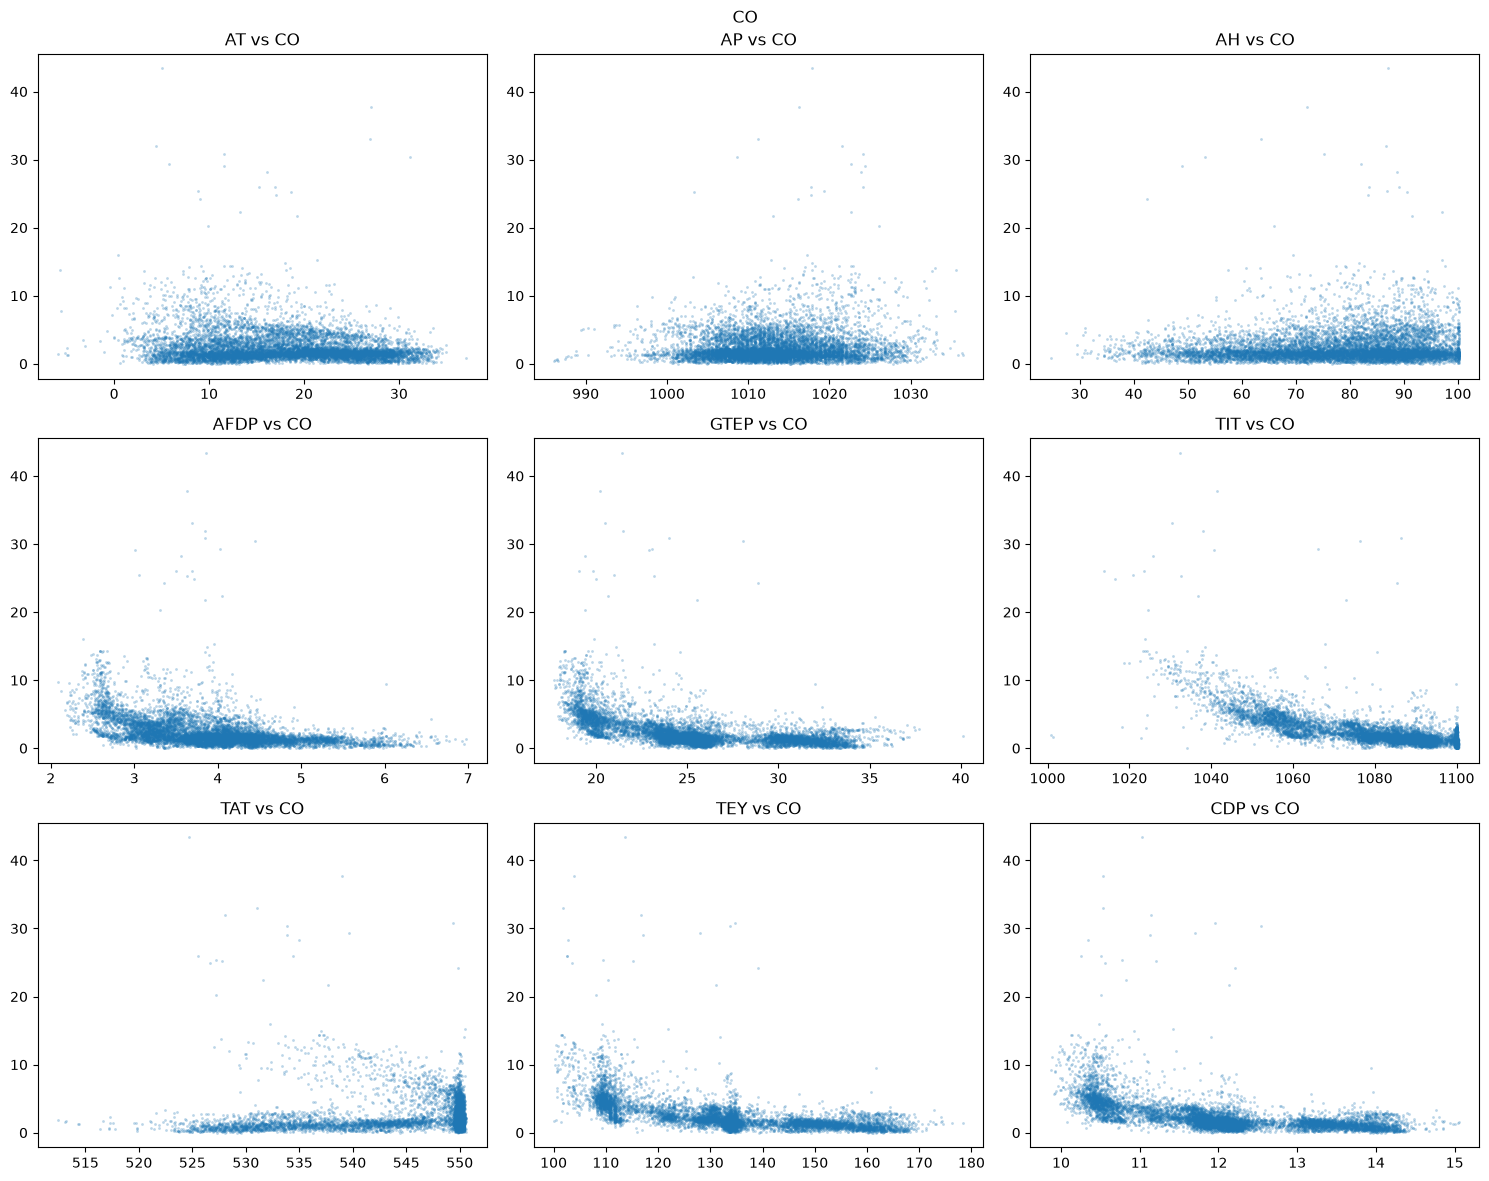

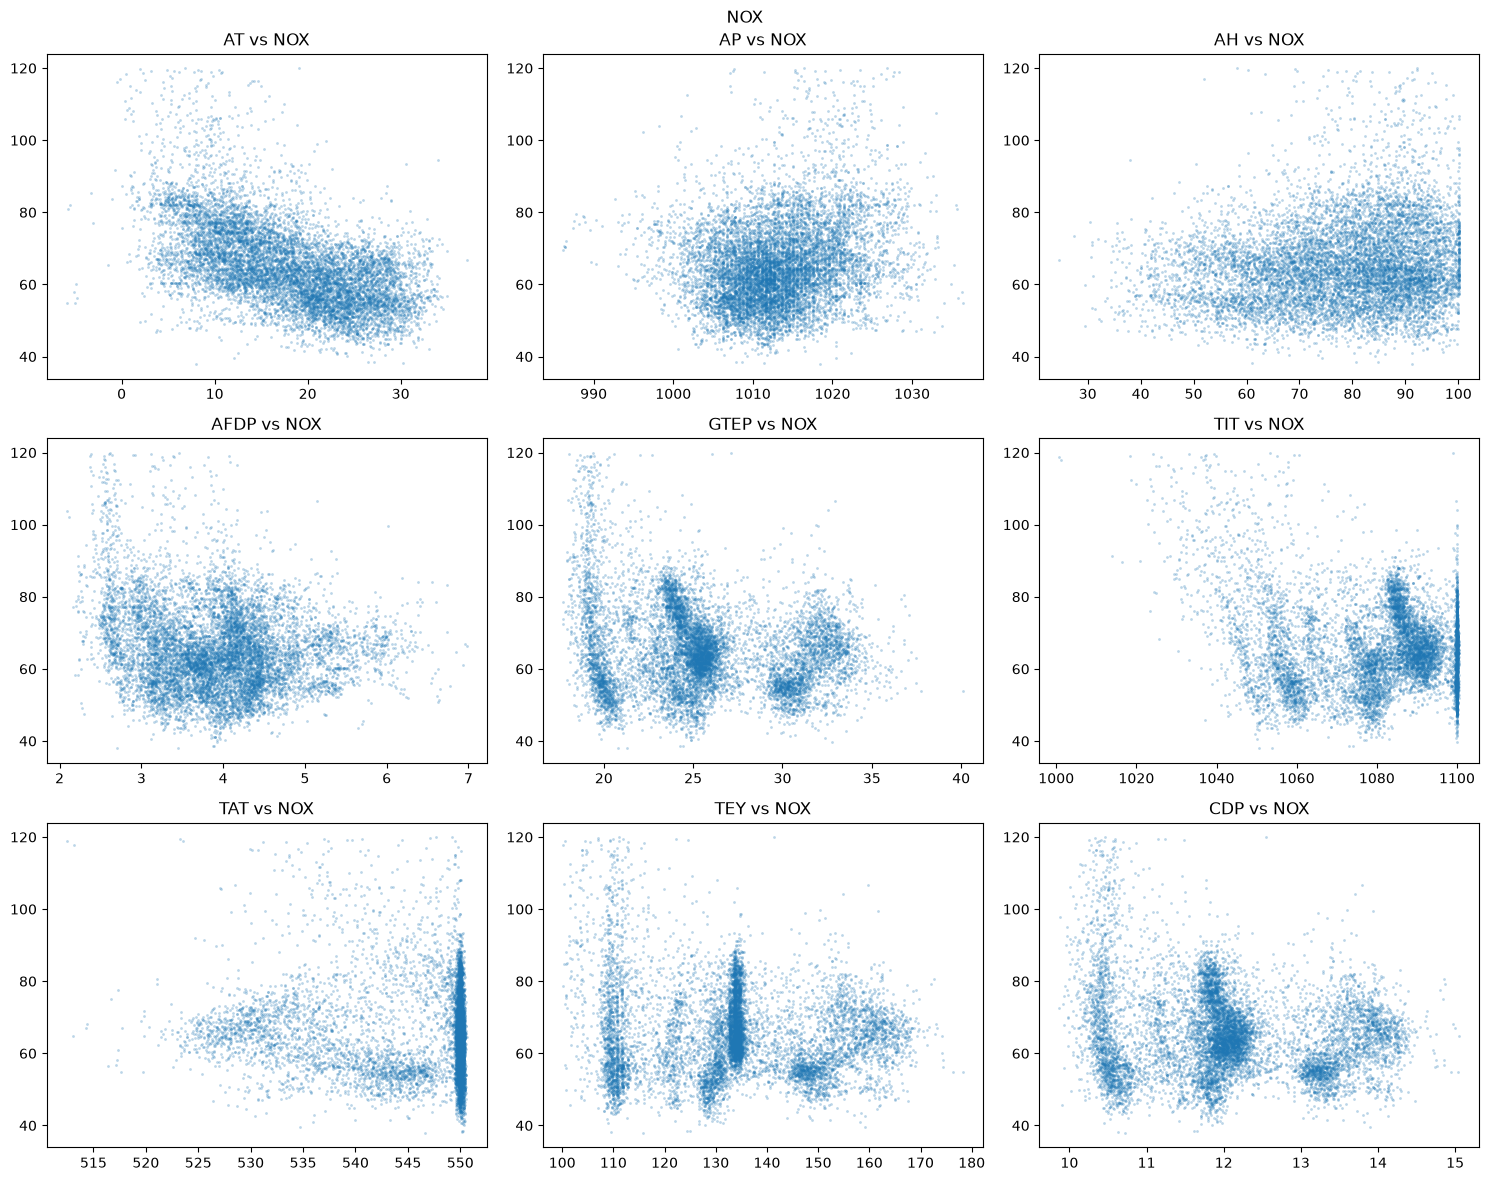

In [13]:
ncols = 3
nrows = math.ceil(len(feature_cols) / ncols)

for target in TARGETS:
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = axes.flatten()

    for ax, col in zip(axes, feature_cols):
        sns.scatterplot(data=sample, x=col, y=target, s=4, alpha=0.3, linewidth=0, ax=ax)
        ax.set_title(f"{col} vs {target}")
        ax.set_xlabel("")
        ax.set_ylabel("")

    for ax in axes[len(feature_cols):]:
        ax.set_visible(False)

    fig.suptitle(target)
    plt.tight_layout()
    plt.show()

In [14]:
pd.concat({"pearson": df[num_cols].corr()[TARGETS], "spearman": df[num_cols].corr(method="spearman")[TARGETS]}, axis=1).drop(index=TARGETS).round(3)

pearson        spearman       
          CO    NOX       CO    NOX
AT    -0.174 -0.558   -0.114 -0.580
AP     0.067  0.192    0.033  0.194
AH     0.107  0.165    0.081  0.150
AFDP  -0.448 -0.188   -0.536 -0.140
GTEP  -0.519 -0.202   -0.639 -0.154
TIT   -0.706 -0.214   -0.698 -0.078
TAT    0.058 -0.093    0.184 -0.085
TEY   -0.570 -0.116   -0.672 -0.004
CDP   -0.551 -0.171   -0.675 -0.108